# Module 12.1 — Pretrained Embeddings 🧠

Yuva, you've already covered Word2Vec, GloVe, and FastText. Now we'll learn how to use embeddings that someone has already trained inside your own NLP model, instead of training them from scratch.

## 1. Why do we need pretrained embeddings?

Imagine you're building a sentiment classifier for customer reviews.

Your dataset might contain only 5,000 reviews. Training Word2Vec from scratch on that small dataset may not give you good word representations because the model has limited text to learn from.

Instead, you can load embeddings trained on a much larger text corpus and reuse the knowledge they have learned.

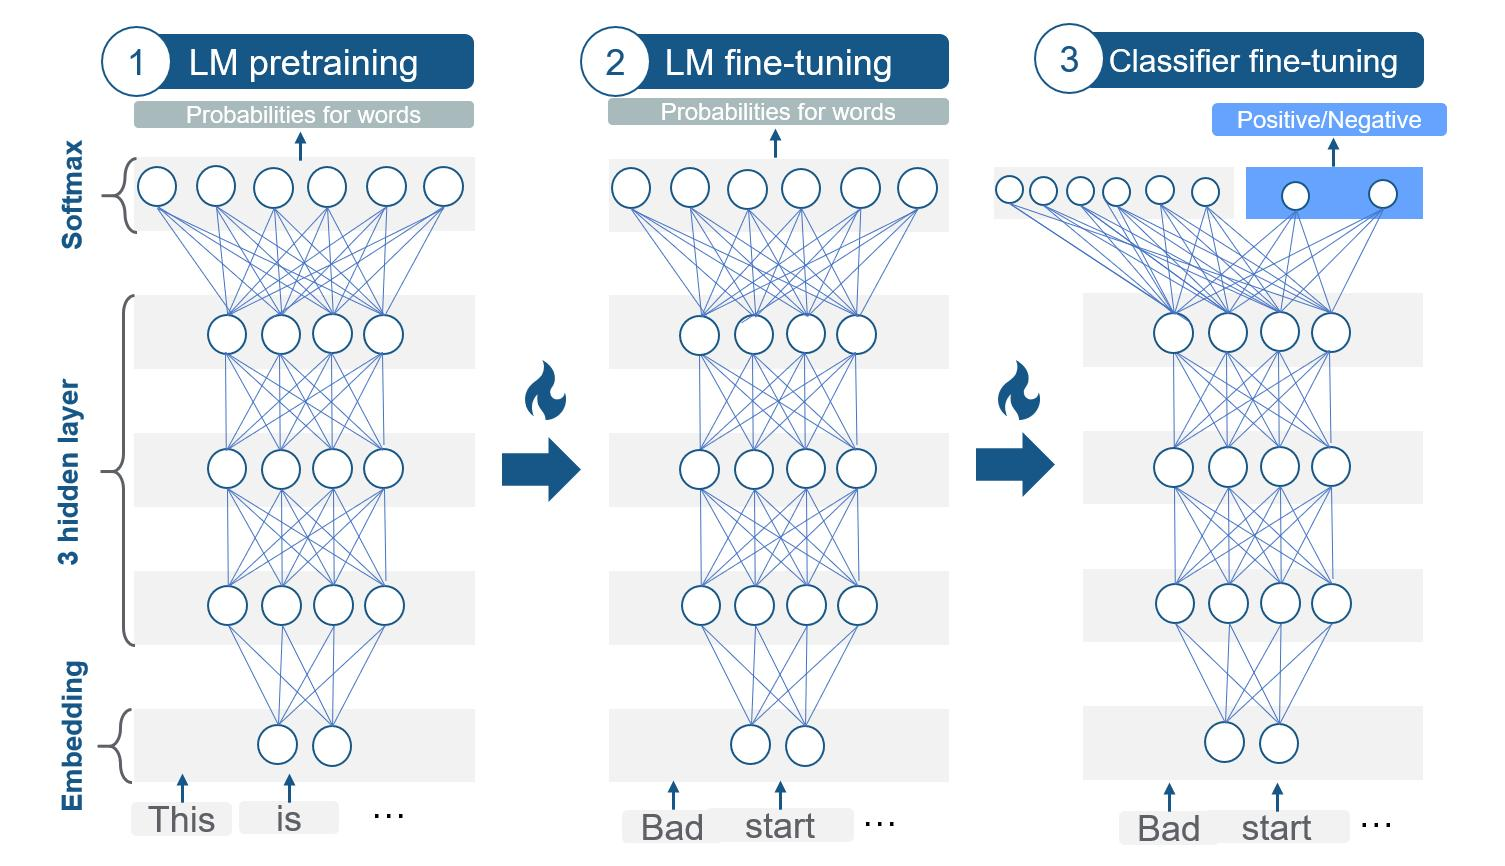

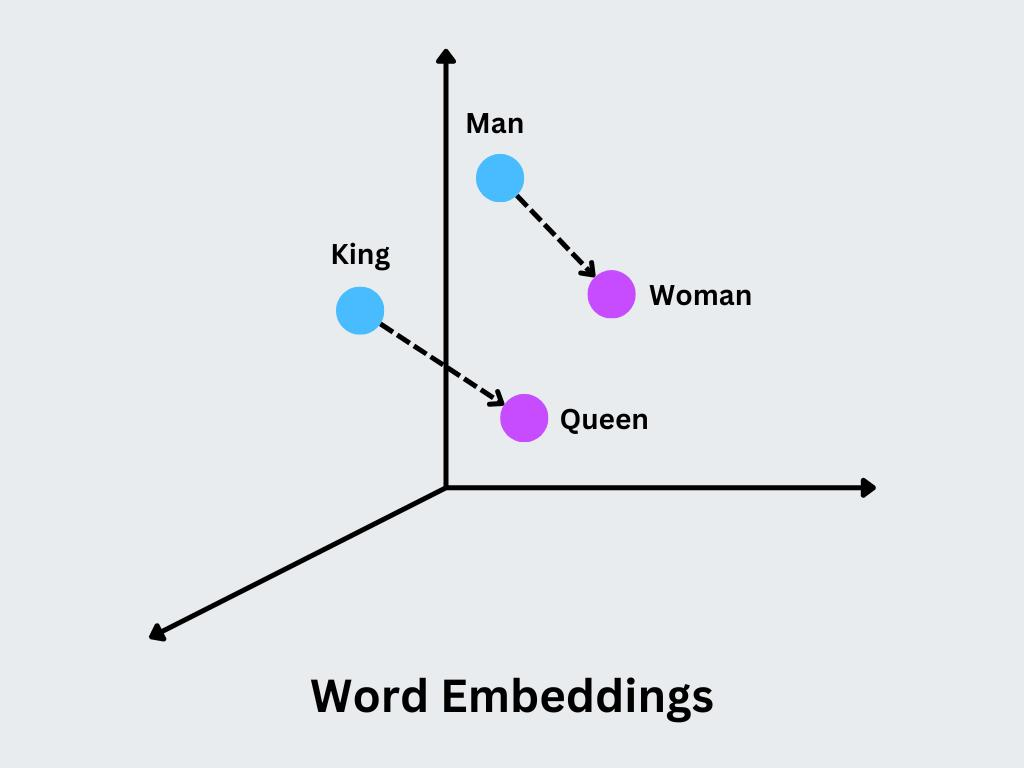



The basic workflow is:

Pretrained embeddings (Word2Vec / GloVe / FastText)

Match your dataset's vocabulary

Construct an embedding matrix

Use it in your NLP model

Key idea: pretrained embeddings provide an initialization for your model's word representations. Depending on your training strategy, you can freeze these vectors or fine-tune them on your own dataset.

## 2. Loading pretrained vectors

Suppose a pretrained embedding model contains 100-dimensional vectors.

Each word is represented by a vector:

\\[ \text{Embedding}(\text{good})\in\mathbb{R}^{100} \\]

A commonly used resource is GloVe, which provides pretrained word vectors learned from large text corpora.

Official resource: [Stanford GloVe pretrained vectors](https://nlp.stanford.edu/projects/glove/). For learning, the 50-dimensional GloVe vectors are a manageable starting point; larger versions require more memory.


## 3. Vocabulary matching

This is the most important part of the implementation.

Suppose your dataset has these words:

```
vocab = {    "<PAD>": 0,    "<UNK>": 1,    "good": 2,    "movie": 3,    "bad": 4}
```

Your pretrained embedding file might contain thousands of other words, but your model needs vectors arranged according to your vocabulary's exact token IDs.

For example, if the pretrained file contains:

| Word    | Pretrained vector      |
| ------- | ---------------------- |
| `movie` | \\([0.2, 0.5, 0.1]\\)  |
| `good`  | \\([0.8, 0.3, 0.4]\\)  |
| `bad`   | \\([-0.5, 0.1, 0.2]\\) |

The embedding matrix must follow your vocabulary order, not the order in the pretrained file.

## 4. Unknown words (OOV)

OOV means out of vocabulary: a word in your dataset that is missing from the pretrained vectors.

For example, your dataset contains `cinematic`, but the embedding file has no vector for it.

Common strategies:

- `<UNK>` token: map missing words to a shared unknown vector.
- Random initialization: initialize missing word vectors randomly and let training improve them.
- FastText: use character n-gram information to construct vectors for many unseen words, provided the required subword information is available.
- Subword tokenization: split words into smaller units; this is especially important in modern Transformer models.

One subtle point: a pretrained model's vocabulary and your dataset vocabulary are not necessarily identical. Also, lowercase matching (`Movie` versus `movie`) depends on the embedding resource and your preprocessing choices.

## 5. Construct the embedding matrix

If your vocabulary has \\(V\\) tokens and each pretrained vector has dimension \\(D\\), the matrix is

\\[ E\in\mathbb{R}^{V\times D} \\]

For the example above, \\(V=5\\) and \\(D=3\\), so the matrix has shape \\(5\times3\\).

Embedding matrix layout

Token ID

Embedding vector

0 — \<PAD>

[0, 0, 0]

1 — \<UNK>

[random values]

2 — good

[0.8, 0.3, 0.4]

3 — movie

[0.2, 0.5, 0.1]

4 — bad

[-0.5, 0.1, 0.2]

Illustrative vectors only. The actual values depend on the pretrained embedding resource.

Notice that `<PAD>` uses a zero vector here. `<UNK>` is initialized separately, rather than assuming every unknown word has a meaningful pretrained vector.

---

In [2]:
import numpy as np 

embedding_dim = 50 
embedding_path = 'glove.6B.50d.txt'

pretrained = {}

with open(embedding_path,encoding='utf') as f:
    for line in f:
        values = line.strip().split()
        word = values[0]
        vector = np.asarray(values[1:], dtype=np.float32)

        if len(vector) == embedding_dim:
            pretrained[word] = vector

print("Loaded words: ", len(pretrained))
print('Vector Shape: ',pretrained['king'].shape)

Loaded words:  400000
Vector Shape:  (50,)


In [9]:
# Build our embedding matrix

import torch

vocab = {
    "<PAD>": 0,
    "<UNK>": 1,
    "good": 2,
    "movie": 3,
    "bad": 4,
    "cinematic": 5
}

embedding_matrix = np.random.normal(
    0, 0.1, (len(vocab), embedding_dim)
).astype(np.float32)

embedding_matrix[vocab["<PAD>"]] = 0.0

found = 0

for word, idx in vocab.items():
    if word in ("<PAD>", "<UNK>"):
        continue

    if word in pretrained:
        embedding_matrix[idx] = pretrained[word]
        found += 1

print("Matched words:", found)
print("Matrix shape:", embedding_matrix.shape)

Matched words: 4
Matrix shape: (6, 50)


In [10]:
embedding_matrix[:,:10]

array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [-0.19688451, -0.09575042, -0.16711958,  0.05510269,  0.01238763,
         0.05847009, -0.14911158,  0.06669716,  0.00355572, -0.05398599],
       [-0.35586   ,  0.5213    , -0.6107    , -0.30131   ,  0.94862   ,
        -0.31539   , -0.59831   ,  0.12188   , -0.031943  ,  0.55695   ],
       [ 0.30824   ,  0.17223   , -0.23339   ,  0.023105  ,  0.28522   ,
         0.23076   , -0.41048   , -1.0035    , -0.2072    ,  1.4327    ],
       [-0.17981   , -0.40407   , -0.1653    , -0.60687   , -0.39656   ,
         0.12688   , -0.053049  ,  0.38024   , -0.51008   ,  0.46593   ],
       [ 0.054939  ,  0.1126    , -1.0481    ,  0.0030723 ,  0.041032  ,
         0.076195  ,  0.43812   , -0.63576   ,  0.002549  ,  1.8489    ]],
      dtype=float32)

In [11]:
# Creating the Embedding layer 

import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = torch.tensor(embedding_matrix)

embedding_layer = nn.Embedding.from_pretrained(
    weights,
    freeze=True,
    padding_idx=vocab["<PAD>"]
).to(device)

token_ids = torch.tensor(
    [vocab["good"], vocab["movie"]],
    dtype=torch.long,
    device=device
)

vectors = embedding_layer(token_ids)

print("Device:", device)
print("Output shape:", vectors.shape)

Device: cuda
Output shape: torch.Size([2, 50])
